# Automated Passenger Boarding Kiosk: walkthrough

Every rubric code item, run against the live Azure services. Run cells top to bottom from the repo root's `.venv`
kernel. Settings come from `.env` (see `.env.example`). Terms are defined in `GLOSSARY.md`, and the rules in
`docs/validation-rules.md`.

| Brief (2022) | Service used here |
|---|---|
| Form Recognizer | Azure AI Document Intelligence |
| FOTT labeling tool | Document Intelligence label files (`*.labels.json`, `*.ocr.json`) in Blob |
| Video Analyzer | Azure AI Video Indexer |
| Face API | Azure AI Face |
| Custom Vision | Azure AI Custom Vision |

In [1]:
import inspect, json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from IPython.display import Image, display, Markdown
from kiosk.services import docintel, storage, face, videoindexer as vi, customvision as cv
from kiosk import manifest as m
print("repo:", ROOT)

repo: /Users/sebastienhenry/Documents/Projects/Udacity/AI Engineer using Azure/Auto Passenger Boarding Kiosk


## Python libraries used

In [2]:
print((ROOT / "requirements.txt").read_text())

azure-ai-documentintelligence==1.0.2
azure-ai-vision-face==1.0.0b2
azure-cognitiveservices-vision-customvision==3.1.1
azure-storage-blob==12.25.1
azure-identity==1.21.0
msrest==0.7.1
requests==2.32.3
python-dotenv==1.1.0
pandas==2.2.3
python-dateutil==2.9.0.post0
python-docx==1.1.2
pypdf==5.4.0
Pillow==11.2.1



## Step 1: Flight Manifest in Blob Storage

In [3]:
blob = storage.service_client()
for name in storage.CONTAINERS:
    print(f"{name:26s}", storage.list_blobs(blob, name)[:8])
m.load_manifest("data/manifest/FlightManifest_initial.csv")

manifest                   ['FlightManifest_final.csv', 'FlightManifest_initial.csv']
digital-ids                ['ca-dl-avkash.png', 'ca-dl-james-jackson.png', 'ca-dl-james-webb.png', 'ca-dl-libby-herold.png', 'ca-dl-radha-s-kumar.png', 'ca-dl-sameer-kumar.png']


boarding-passes            ['boarding-avkash.pdf', 'boarding-james-webb.pdf', 'boarding-james.pdf', 'boarding-libby.pdf', 'boarding-radha-s-kumar.pdf', 'boarding-sameer.pdf']
training-boarding-passes   ['fields.json', 'training-pass-01.pdf', 'training-pass-01.pdf.labels.json', 'training-pass-01.pdf.ocr.json', 'training-pass-02.pdf', 'training-pass-02.pdf.labels.json', 'training-pass-02.pdf.ocr.json', 'training-pass-03.pdf']
identity-videos            ['avkash-boarding-pass.mp4']


luggage-scans              ['lighter_test_set_1of5.jpg', 'lighter_test_set_2of5.jpg', 'lighter_test_set_3of5.jpg', 'lighter_test_set_4of5.jpg', 'lighter_test_set_5of5.jpg']
kiosk-results              ['34236746.json', '34236747.json', '34236748.json', '34236749.json', '34236750.json', '34236751.json', '34236751_identity_report.json', 'lighter_predictions.json']


,TicketNo,FirstName,LastName,DateOfBirth,Sex,Carrier,FlightNo,Class,From,To,Date,Baggage,Seat,Gate,BoardingTime,NameValidation,DoBValidation,PersonValidation,BoardingPassValidation,LuggageValidation
0,34236746,Sameer,Kumar,1990-01-25,M,UA,234,Economy,San Francisco,Chicago,"April 20, 2022",YES,34A,G1,10:00 AM PST,False,False,False,False,False
1,34236747,Radha S.,Kumar,1994-03-05,F,UA,234,Economy,San Francisco,Chicago,"April 20, 2022",YES,34B,G1,10:00 AM PST,False,False,False,False,False
2,34236748,James,Webb,1970-12-16,M,UA,234,Business,San Francisco,Chicago,"April 20, 2022",No,1A,G1,10:00 AM PST,False,False,False,False,False
3,34236749,Libby,Herold,1996-02-10,F,UA,234,Business,San Francisco,Chicago,"April 20, 2022",No,3D,G1,10:00 AM PST,False,False,False,False,False
4,34236750,James,Jackson,1956-10-12,M,UA,234,Economy,San Francisco,Chicago,"April 20, 2022",YES,25B,G1,10:00 AM PST,False,False,False,False,False
5,34236751,Avkash,Chauhan,1990-01-01,M,UA,234,Economy,San Francisco,Chicago,"April 20, 2022",No,20A,G1,10:00 AM PST,False,False,False,False,False


## Step 2a: Digital ID with the prebuilt ID model

In [4]:
print(inspect.getsource(docintel.analyze)); print(inspect.getsource(docintel.parse_id_document))

def analyze(path: Path, model_id: str, di: DocumentIntelligenceClient | None = None) -> dict[str, Any]:
    """Analyze a local file. Offsets use UTF-16 code units, matching what Document Intelligence Studio stores."""
    di = di or client()
    with path.open("rb") as handle:
        poller = di.begin_analyze_document(
            model_id, body=handle, content_type="application/octet-stream", string_index_type="utf16CodeUnit"
        )
    return poller.result().as_dict()

def parse_id_document(result: dict[str, Any]) -> IdDocument:
    fields = _documents(result)[0].get("fields") or {}
    return IdDocument(
        first_name=field_text(fields, "FirstName"),
        last_name=field_text(fields, "LastName"),
        date_of_birth=field_text(fields, "DateOfBirth"),
        sex=field_text(fields, "Sex"),
    )



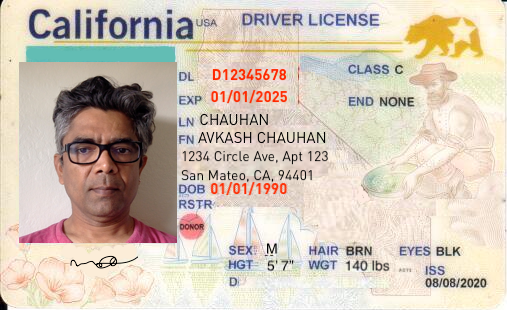

FirstName    AVKASH CHAUHAN       confidence=0.78
LastName     CHAUHAN              confidence=0.70
DateOfBirth  1990-01-01           confidence=0.66
Sex          M                    confidence=0.49


In [5]:
id_doc, raw = docintel.extract_id(Path("starter/digital_id_template/ca-dl-avkash.png"))
display(Image("starter/digital_id_template/ca-dl-avkash.png", width=420))
fields = raw["documents"][0]["fields"]
for k in ("FirstName", "LastName", "DateOfBirth", "Sex"):
    print(f"{k:12s} {docintel.field_text(fields, k):20s} confidence={fields[k]['confidence']:.2f}")

## Step 2b: Custom boarding-pass model, trained from labeled passes in Blob

In [6]:
print(storage.list_blobs(blob, "training-boarding-passes")[:12], "...")
print(json.dumps(json.loads(Path("data/training_boarding_passes/training-pass-01.pdf.labels.json").read_text())["labels"][0], indent=1)[:600])

['fields.json', 'training-pass-01.pdf', 'training-pass-01.pdf.labels.json', 'training-pass-01.pdf.ocr.json', 'training-pass-02.pdf', 'training-pass-02.pdf.labels.json', 'training-pass-02.pdf.ocr.json', 'training-pass-03.pdf', 'training-pass-03.pdf.labels.json', 'training-pass-03.pdf.ocr.json', 'training-pass-04.pdf', 'training-pass-04.pdf.labels.json'] ...
{
 "label": "PassengerName",
 "key": null,
 "value": [
  {
   "page": 1,
   "text": "Grace",
   "boundingBoxes": [
    [
     0.18207272727272727,
     0.27365882352941173,
     0.21839090909090908,
     0.27380000000000004,
     0.21839090909090908,
     0.2902823529411765,
     0.18210909090909091,
     0.29012941176470586
    ]
   ]
  },
  {
   "page": 1,
   "text": "Brown",
   "boundingBoxes": [
    [
     0.22316363636363637,
     0.27385882352941177,
     0.26320909090909095,
     0.27392941176470587,
     0.26320909090909095,
     0.29014117647058824,
     0.22317272727272727,
     0.29


In [7]:
import scripts.train_boarding_pass_model as t
print(inspect.getsource(t.main))
model = json.loads(Path("data/out/boarding_pass_model.json").read_text())
print("model:", model["modelId"], "| estimated field accuracy:", next(iter(model["docTypes"].values()))["fieldConfidence"])

def main() -> None:
    di = docintel.client()
    missing = label_all(di)
    incomplete = {doc: fields for doc, fields in missing.items() if fields}
    if incomplete:
        raise SystemExit(f"labels incomplete, fix before training: {incomplete}")

    blob = storage.service_client()
    upload_all(blob)

    admin = DocumentIntelligenceAdministrationClient(setting("DOCINTEL_ENDPOINT"), AzureKeyCredential(setting("DOCINTEL_KEY")))
    model_id = setting("BOARDING_PASS_MODEL_ID")
    request = BuildDocumentModelRequest(
        model_id=model_id,
        build_mode=DocumentBuildMode.TEMPLATE,
        description="Udacity boarding pass extractor (template model, synthetic training passes)",
        azure_blob_source=AzureBlobContentSource(container_url=container_sas_url(blob)),
    )
    model = admin.begin_build_document_model(request).result()
    doc_type = next(iter(model.doc_types.values()))
    logging.info("trained model %s; field confidence: %s", model.model_id, json.dumps(do

In [8]:
bp, raw = docintel.extract_boarding_pass(Path("starter/boarding_pass_template/boarding-avkash.pdf"))
bp

BoardingPass(passenger_name='Avkash Chauhan', carrier='UA', flight_no='234', travel_class='E', origin='San Francisco', destination='Chicago', flight_date='April 20, 2022', boarding_time='10:00 AM', seat='20A', ticket_no='ETK-34236751E')

## Step 3: Identity video with Video Indexer and Face

In [9]:
print(inspect.getsource(vi.upload_video))
import scripts.analyze_identity_video as a
print(inspect.getsource(a._index))

def upload_video(path: Path, token: str, name: str) -> str:
    """Upload a local video file and start indexing; returns the video id."""
    params = {"accessToken": token, "name": name, "privacy": "Private", "indexingPreset": "Advanced"}
    with path.open("rb") as handle:
        response = requests.post(_account_url("Videos"), params=params, files={"file": (path.name, handle, "video/mp4")}, timeout=600)
    if response.status_code >= 400:
        raise VideoIndexerError(f"upload -> {response.status_code}: {response.text[:300]}")
    return response.json()["id"]

def _index(video: Path, ticket: str, token: str) -> tuple[str, dict]:
    cache = OUT / "video" / f"{ticket}_index.json"
    if cache.exists():
        index = json.loads(cache.read_text())
        return index["id"], index
    video_id = vi.upload_video(video, token, name=f"identity-{ticket}")
    logging.info("uploaded %s to Video Indexer as %s", video.name, video_id)
    index = vi.wait_for_index(video_id, token)
    cac

video id: cxq1we43ml | state: Processed
face thumbnails: {1000: ['8f55137c-2f1a-4799-8c0c-3d56becd92f8', '9721dd9f-1664-4fb5-8faa-419959c1fe16', '0078a318-9377-413d-ba98-13cfda40273c', '5eb92d76-6b6f-4640-ac89-b37f86c16ed6', '876382fc-90ab-4245-bd3e-4002daaf2566', 'ea4e5bcc-5867-480c-acdc-39c4b106333d', '41002a4a-6c4e-4ea5-9158-e3a5fbb45dfc']}


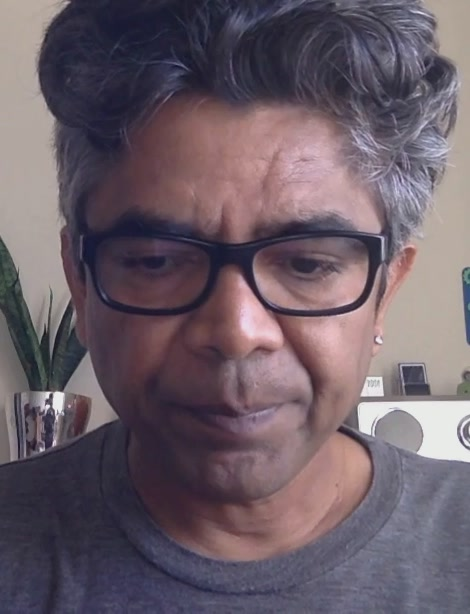

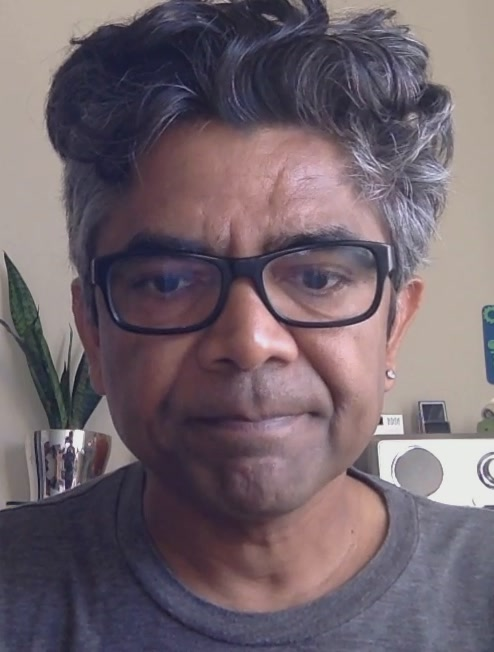

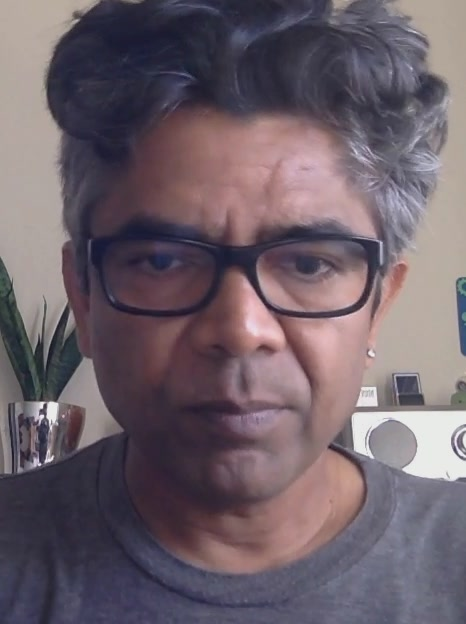

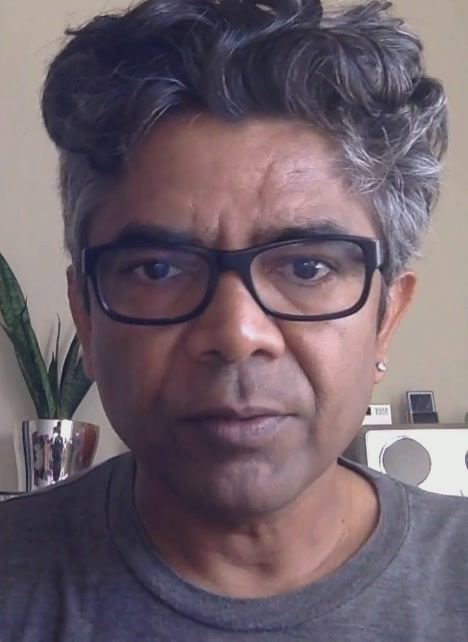

In [10]:
index = json.loads(Path("data/out/video/34236751_index.json").read_text())
print("video id:", index["id"], "| state:", index["state"])
thumbs = sorted(Path("data/out/video/34236751_faces").glob("*.jpg"))
print("face thumbnails:", vi.face_thumbnail_ids(index))
for p in thumbs[:4]: display(Image(str(p), width=120))

### Person model from the video face frames, matched with the ID face

In [11]:
print(inspect.getsource(face.build_person_group)); print(inspect.getsource(face.identify))

def build_person_group(group_id: str, person_name: str, face_images: Iterable[bytes]) -> tuple[str, int]:
    """Create (or recreate) a person group with one person trained on the given face images."""
    if _exists(group_id):
        _call("DELETE", f"persongroups/{group_id}", headers=_headers())
    _call("PUT", f"persongroups/{group_id}", headers=_headers(), json={"name": group_id, "recognitionModel": RECOGNITION_MODEL})
    person_id = _call("POST", f"persongroups/{group_id}/persons", headers=_headers(), json={"name": person_name})["personId"]
    added = 0
    for image in face_images:
        try:
            _call(
                "POST",
                f"persongroups/{group_id}/persons/{person_id}/persistedfaces",
                params={"detectionModel": DETECTION_MODEL},
                headers=_headers("application/octet-stream"),
                data=image,
            )
            added += 1
        except FaceError as exc:
            log.warning("skipped a face frame:

In [12]:
id_face = face.single_face_id(face.detect(Path("starter/digital_id_template/ca-dl-avkash.png").read_bytes()))
person_id, n_faces = face.build_person_group("passenger-34236751", "Avkash Chauhan", (p.read_bytes() for p in thumbs))
candidates = face.identify("passenger-34236751", id_face)[0]["candidates"]
print(f"person model trained on {n_faces} video face frames")
print(f"ID face vs person model: {candidates[0]['confidence']:.1%} match (threshold 65%)")
best = face.best_confidence(face.verify(id_face, face.single_face_id(face.detect(p.read_bytes()))) for p in thumbs)
print(f"best direct verify, ID vs a video frame: {best:.1%}")

person model trained on 7 video face frames
ID face vs person model: 95.7% match (threshold 65%)


best direct verify, ID vs a video frame: 95.8%


### Emotion and sentiment from Video Indexer

In [13]:
ins = index["videos"][0]["insights"]
print("emotions:", ins.get("emotions", []))
print("sentiments:", [(s["sentimentType"], s["averageScore"]) for s in ins.get("sentiments", [])])
vi.passenger_feedback(index)

emotions: []
sentiments: [('Neutral', 0.5)]


{'label': 'neutral',
 'dominant_emotion': None,
 'emotions': {},
 'sentiments': {'Neutral': {'seconds': 26.634, 'average_score': 0.5}}}

## Step 4: Lighter detection with Custom Vision

In [14]:
from kiosk.config import setting
print(json.dumps(json.loads(Path("data/out/lighter_model.json").read_text()), indent=1))
print(inspect.getsource(cv.predict_lighter))

{
 "iteration": "Iteration 3",
 "training_type": "Advanced (1-hour budget)",
 "precision": 1.0,
 "recall": 0.4117647,
 "mAP": 0.92362636,
 "prediction_endpoint": "https://kiosk-prediction-305856.cognitiveservices.azure.com/customvision/v3.0/Prediction/c8daa25a-0ff8-44fc-8273-594597c91091/detect/iterations/lighter-detector/image",
 "previous": {
  "iteration": "Iteration 2",
  "training_type": "Quick",
  "precision": 1.0,
  "recall": 0.1764706,
  "mAP": 0.8157572
 }
}
def predict_lighter(client: CustomVisionPredictionClient, project_id: str, image: Path) -> tuple[float, list[dict[str, Any]]]:
    with image.open("rb") as handle:
        result = client.detect_image(project_id, setting("CUSTOM_VISION_PUBLISHED_NAME"), handle)
    regions = [
        {"tag": p.tag_name, "probability": p.probability, "box": p.bounding_box.as_dict() if p.bounding_box else None}
        for p in result.predictions
    ]
    return max_tag_probability(result.predictions), regions



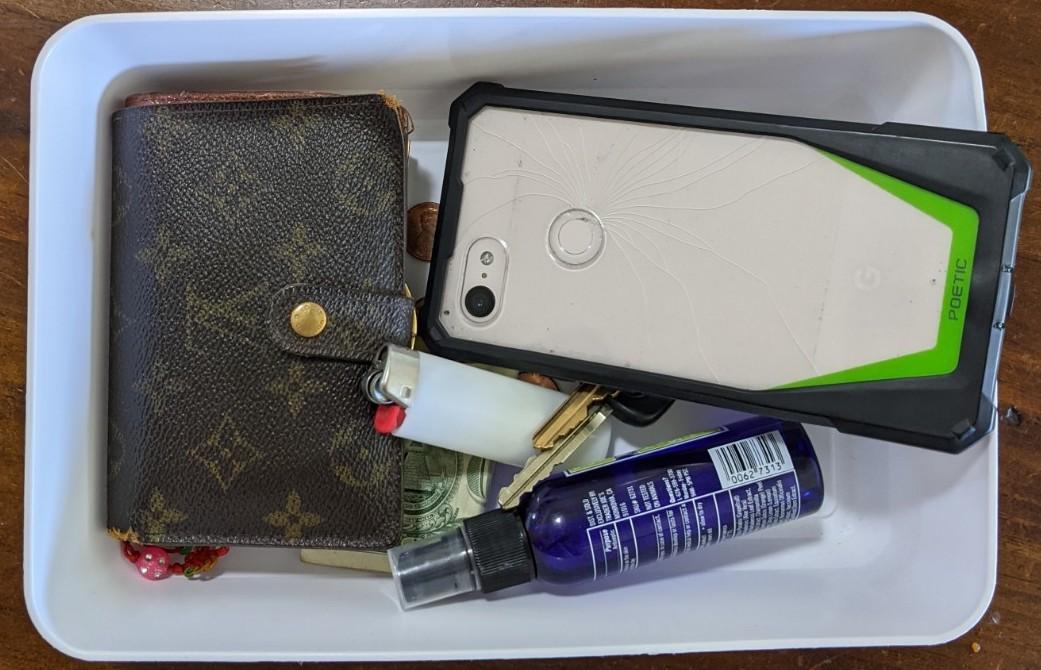

lighter_test_set_1of5.jpg: lighter probability 52.1%


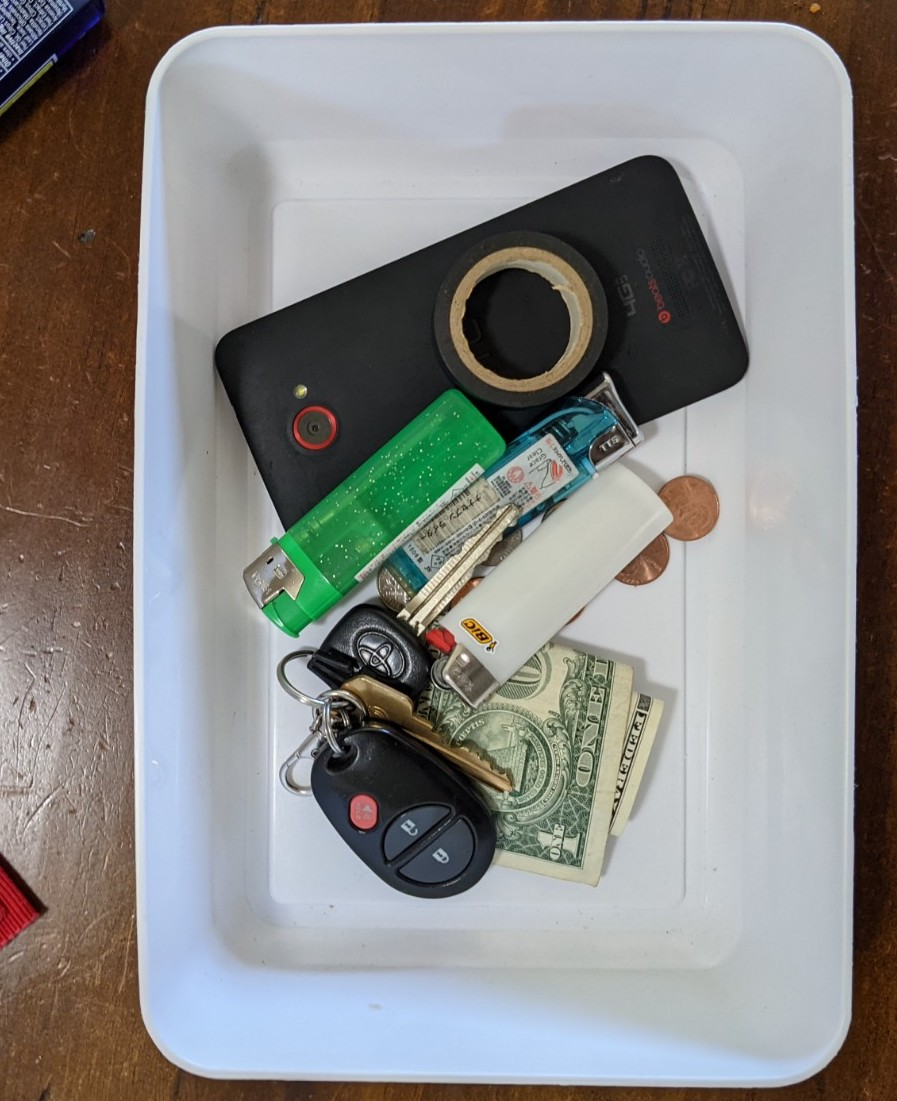

lighter_test_set_2of5.jpg: lighter probability 78.1%


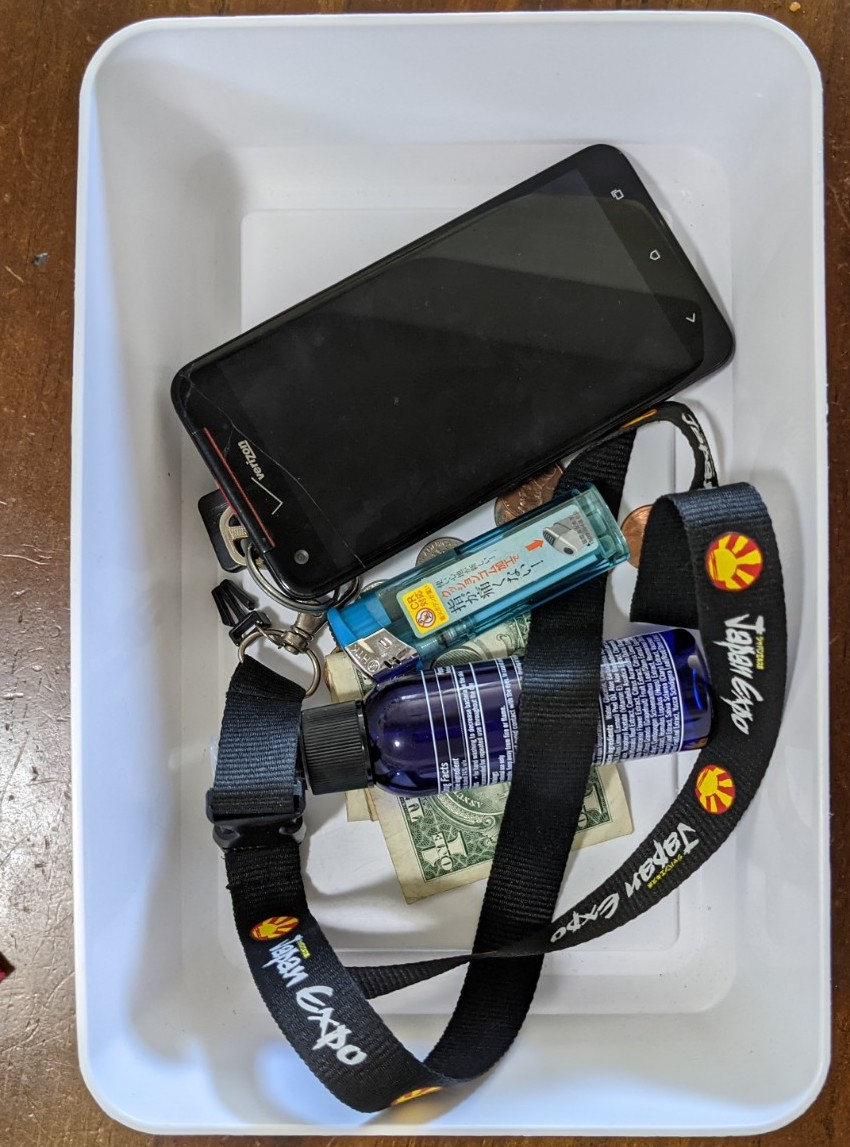

lighter_test_set_3of5.jpg: lighter probability 29.5%


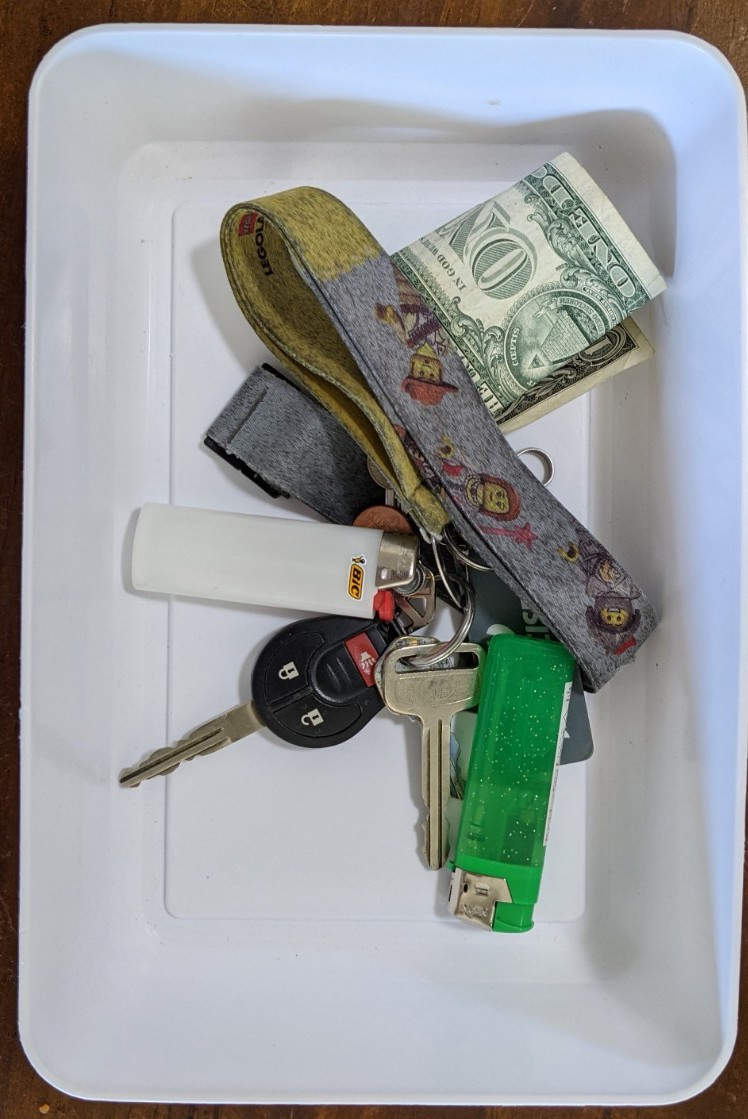

lighter_test_set_4of5.jpg: lighter probability 84.1%


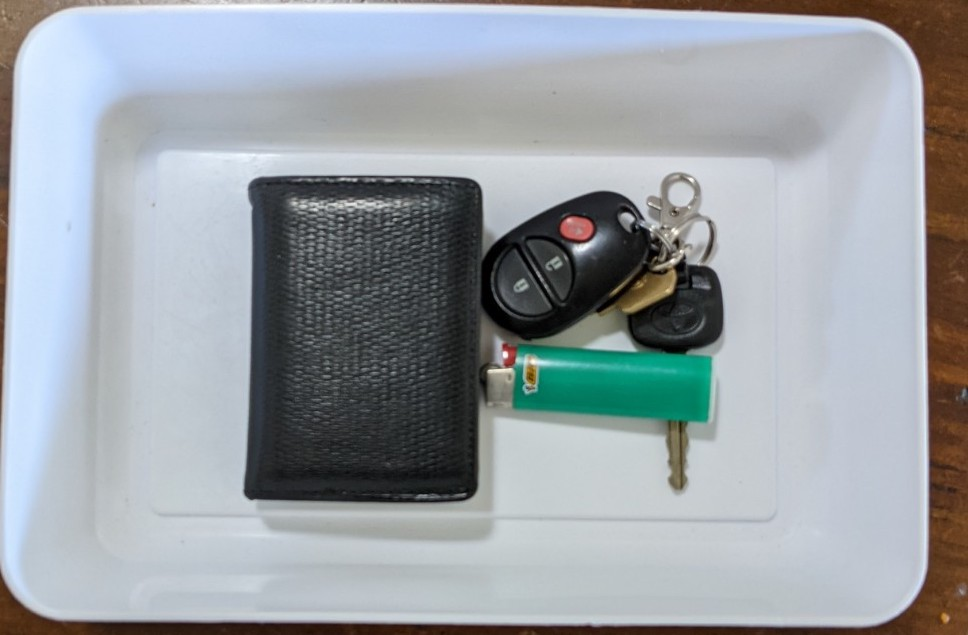

lighter_test_set_5of5.jpg: lighter probability 13.7%


In [15]:
pred = cv.predictor(); pid = setting("CUSTOM_VISION_PROJECT_ID")
for img in sorted(Path("starter/lighter_test_images").glob("*.jpg")):
    p, regions = cv.predict_lighter(pred, pid, img)
    display(Image(str(img), width=260)); print(f"{img.name}: lighter probability {p:.1%}")

## Step 5: Validation, manifest update and kiosk messages

In [16]:
from kiosk.pipeline import process_passenger
from kiosk.models import PersonMatch, LuggageScan
import scripts.run_kiosk as rk
print(inspect.getsource(rk.main))

def main(refresh: bool = False) -> None:
    truth = {k: v for k, v in json.loads((ROOT / "data/ground_truth.json").read_text()).items() if not k.startswith("_")}
    frame = m.load_manifest(ROOT / "data/manifest/FlightManifest_initial.csv")
    rows = m.to_rows(frame)
    persons, scans = _load_optional("person_matches.json"), _load_optional("luggage_scans.json")
    di = docintel.client()
    blob = storage.service_client()

    for ticket, files in truth.items():
        id_path = STARTER / "digital_id_template" / files["digital_id"]
        bp_path = STARTER / "boarding_pass_template" / files["boarding_pass"]
        id_doc = docintel.parse_id_document(_cached("ids", ticket, refresh, lambda: docintel.extract_id(id_path, di)))
        bp = docintel.parse_boarding_pass(_cached("boarding_passes", ticket, refresh, lambda: docintel.extract_boarding_pass(bp_path, di)))
        person = PersonMatch(**persons[ticket]) if ticket in persons else None
        scan = LuggageScan.scanned(**scan

In [17]:
import subprocess
print(subprocess.run([sys.executable, "-m", "scripts.run_kiosk"], capture_output=True, text=True).stderr[-6000:])


=== Sameer Kumar (34236746) 3/5 passed {'NameValidation': True, 'DoBValidation': True, 'PersonValidation': False, 'BoardingPassValidation': True, 'LuggageValidation': False}
Dear Mr. Sameer Kumar,
You are welcome to flight # UA234 leaving at 10:00 AM from San Francisco to Chicago.
Your seat number is 34A, and it is confirmed.
We have found a prohibited item in your carry-on baggage, and it is flagged for removal.
Your identity could not be verified. Please see a customer service representative.

=== Radha S. Kumar (34236747) 3/5 passed {'NameValidation': True, 'DoBValidation': True, 'PersonValidation': False, 'BoardingPassValidation': True, 'LuggageValidation': False}
Dear Ms. Radha S. Kumar,
You are welcome to flight # UA234 leaving at 10:00 AM from San Francisco to Chicago.
Your seat number is 34B, and it is confirmed.
We have found a prohibited item in your carry-on baggage, and it is flagged for removal.
Your identity could not be verified. Please see a customer service representa

In [18]:
final = m.load_manifest("data/manifest/FlightManifest_final.csv")
final[["TicketNo", "FirstName", "LastName", *m.VALIDATION_COLUMNS]]

,TicketNo,FirstName,LastName,NameValidation,DoBValidation,PersonValidation,BoardingPassValidation,LuggageValidation
0,34236746,Sameer,Kumar,True,True,False,True,False
1,34236747,Radha S.,Kumar,True,True,False,True,False
2,34236748,James,Webb,True,False,False,True,True
3,34236749,Libby,Herold,True,True,False,True,False
4,34236750,James,Jackson,True,True,False,True,True
5,34236751,Avkash,Chauhan,True,True,True,True,False
